<a href="https://colab.research.google.com/github/Lillie-Walden/Lab-4/blob/main/Assignments/assignment_09_clustering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# IS 4487 Assignment 9: Customer Segmentation with Clustering

In this assignment, you will:
- Apply unsupervised learning to explore patterns in hotel booking behavior
- Use K-Means and Gaussian Mixture Models (GMM) for customer segmentation
- Evaluate model quality with metrics like Silhouette Score and Davies-Bouldin Index
- Connect clustering to actionable business insights

## Why This Matters

Businesses like hotels and travel platforms (e.g., Airbnb or Expedia) rely on customer segmentation to tailor promotions, pricing strategies, and service levels. Unlike supervised models, clustering helps uncover patterns when no labels exist—an ideal tool when entering new markets or analyzing unstructured customer behavior.

<a href="https://colab.research.google.com/github/Stan-Pugsley/is_4487_base/blob/main/Assignments/assignment_09_clustering.ipynb" target="_parent">
  <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
</a>


## Dataset Description: Hotel Bookings

This dataset contains booking information for two types of hotels: a **city hotel** and a **resort hotel**. Each record corresponds to a single booking and includes various details about the reservation, customer demographics, booking source, and whether the booking was canceled.

**Source**: [GitHub - TidyTuesday: Hotel Bookings](https://github.com/rfordatascience/tidytuesday/blob/master/data/2020/2020-02-11/readme.md)

### Key Use Cases
- Understand customer booking behavior
- Explore factors related to cancellations
- Segment guests based on booking characteristics
- Compare city vs. resort hotel performance

### Data Dictionary

| Variable | Type | Description |
|----------|------|-------------|
| `hotel` | character | Hotel type: City or Resort |
| `is_canceled` | integer | 1 = Canceled, 0 = Not Canceled |
| `lead_time` | integer | Days between booking and arrival |
| `arrival_date_year` | integer | Year of arrival |
| `arrival_date_month` | character | Month of arrival |
| `stays_in_weekend_nights` | integer | Nights stayed on weekends |
| `stays_in_week_nights` | integer | Nights stayed on weekdays |
| `adults` | integer | Number of adults |
| `children` | integer | Number of children |
| `babies` | integer | Number of babies |
| `meal` | character | Type of meal booked |
| `country` | character | Country code of origin |
| `market_segment` | character | Booking source (e.g., Direct, Online TA) |
| `distribution_channel` | character | Booking channel used |
| `is_repeated_guest` | integer | 1 = Repeated guest, 0 = New guest |
| `previous_cancellations` | integer | Past booking cancellations |
| `previous_bookings_not_canceled` | integer | Past bookings not canceled |
| `reserved_room_type` | character | Initially reserved room type |
| `assigned_room_type` | character | Room type assigned at check-in |
| `booking_changes` | integer | Number of booking modifications |
| `deposit_type` | character | Deposit type (No Deposit, Non-Refund, etc.) |
| `agent` | character | Agent ID who made the booking |
| `company` | character | Company ID (if booking through company) |
| `days_in_waiting_list` | integer | Days on the waiting list |
| `customer_type` | character | Booking type: Contract, Transient, etc. |
| `adr` | float | Average Daily Rate (price per night) |
| `required_car_parking_spaces` | integer | Requested parking spots |
| `total_of_special_requests` | integer | Number of special requests made |
| `reservation_status` | character | Final status (Canceled, No-Show, Check-Out) |
| `reservation_status_date` | date | Date of the last status update |

This dataset is ideal for classification, segmentation, and trend analysis exercises.

## 1. Setup and Load Data

### Business framing:  

### Do the following:
Before we can cluster or segment anything, we need clean, accessible data in a usable format.

- Import the necessary Python libraries
- Import data from the hotels dataset into a dataframe (in GitHub go to the DataSets folder and look for `hotels.csv`)
- Display the first few rows
- Show summary statistics for the dataframe

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, davies_bouldin_score

url = "https://raw.githubusercontent.com/Stan-Pugsley/is_4487_base/main/DataSets/hotels.csv"
df = pd.read_csv(url)

df.head()
df.describe()


,is_canceled,lead_time,arrival_date_year,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,booking_changes,agent,company,days_in_waiting_list,adr,required_car_parking_spaces,total_of_special_requests
count,9404.000000,9404.000000,9404.000000,9404.000000,9404.000000,9404.000000,9404.000000,9404.000000,9404.000000,9404.000000,9404.000000,9404.000000,9404.000000,9404.000000,7069.000000,1011.000000,9404.000000,9404.000000,9404.000000,9404.000000
mean,0.248299,79.326244,2015.156104,37.026584,15.515313,1.155040,3.078690,1.864738,0.095279,0.015419,0.077839,0.419715,0.290196,0.238622,200.990946,219.550940,1.019034,86.843614,0.144938,0.613143
std,0.432049,87.584146,0.443661,11.083421,9.025545,1.124304,2.379227,1.198565,0.393858,0.125781,0.267933,2.726546,1.352679,0.630041,80.330753,104.296474,10.137928,53.759940,0.353264,0.835930
min,0.000000,0.000000,2015.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,9.000000,0.000000,-6.380000,0.000000,0.000000
25%,0.000000,8.000000,2015.000000,31.000000,7.000000,0.000000,1.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,156.000000,135.000000,0.000000,45.000000,0.000000,0.000000
50%,0.000000,48.000000,2015.000000,38.000000,16.000000,1.000000,3.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,240.000000,223.000000,0.000000,71.550000,0.000000,0.000000
75%,0.000000,118.000000,2015.000000,45.000000,23.000000,2.000000,5.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,241.000000,286.000000,0.000000,120.600000,0.000000,1.000000
max,1.000000,737.000000,2017.000000,53.000000,31.000000,13.000000,33.000000,55.000000,10.000000,2.000000,1.000000,26.000000,26.000000,17.000000,468.000000,511.000000,122.000000,508.000000,2.000000,5.000000


1. What stands out in the initial preview? Any columns or rows that seem unusual?


### Reflection:
1. What stands out in the initial preview? Any columns or rows that seem unusual?

### ✍️ Your Response: 🔧
1. From the initial preview, I notice that there are some missing values in the columns, like agent, company, and children. Some of the bookings also seem to contain a value of 0 for adults, which is odd. There are also outliers in the Average daily rate section , which we need to flag to watch and analyze further.

## 2. Select and Prepare Features

### Business framing:  

A hotel might want to group guests based on how long they stay, how far in advance they book, or how likely they are to make special requests. You need to pick variables that represent meaningful guest behavior.

### Do the following:
- 2.1 Choose 3–5 numeric features related to customer behavior
- 2.2 Perform basic data preparation - remove outliers, remove duplicates, correct any datatypes that need adjustment
- 2.3 Drop missing values if needed
- 2.4 Standardize using `StandardScaler` for any large values  (over 100)

In [4]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler

# 2.1 Choose 5 numeric features related to customer behavior
selected_features = [
    'lead_time',
    'stays_in_weekend_nights',
    'stays_in_week_nights',
    'adr',
    'total_of_special_requests'
]

# Create a working copy of the dataset with only target features for preparation
df_prep = df[selected_features].copy()

# 2.2 & 2.3 Perform basic data preparation
# Remove rows with negative or extreme ADR outliers
df_prep = df_prep[(df_prep['adr'] >= 0) & (df_prep['adr'] < 500)]

# Remove rows with extreme lead_time outliers (e.g., greater than 600 days)
df_prep = df_prep[df_prep['lead_time'] <= 600]

# Drop missing values
df_prep = df_prep.dropna()

# Remove duplicates to ensure unique customer behavior profiles
df_prep = df_prep.drop_duplicates()

# 2.4 Standardize the prepared features using StandardScaler
scaler = StandardScaler()
scaled_features = scaler.fit_transform(df_prep)

# Create a new DataFrame with the scaled features
df_scaled = pd.DataFrame(scaled_features, columns=selected_features)

# Display the cleaned and scaled dataset information
print(f"Original dataset shape: {df.shape}")
print(f"Cleaned, unique, and scaled dataset shape: {df_scaled.shape}")
display(df_scaled.head())
display(df_scaled.describe())

Original dataset shape: (9404, 32)
Cleaned, unique, and scaled dataset shape: (6664, 5)


,lead_time,stays_in_weekend_nights,stays_in_week_nights,adr,total_of_special_requests
0,3.699539,-1.124042,-1.381387,-1.731603,-0.855213
1,-0.815073,-1.124042,-0.971705,-0.380340,-0.855213
2,-0.734214,-1.124042,-0.971705,-0.380340,-0.855213
3,-0.720738,-1.124042,-0.562022,0.034048,0.291726
4,-0.909408,-1.124042,-0.562022,0.196200,-0.855213


,lead_time,stays_in_weekend_nights,stays_in_week_nights,adr,total_of_special_requests
count,6.664000e+03,6.664000e+03,6.664000e+03,6.664000e+03,6.664000e+03
mean,-2.558977e-17,-4.691459e-17,8.529925e-18,8.529925e-17,-6.397444e-18
std,1.000075e+00,1.000075e+00,1.000075e+00,1.000075e+00,1.000075e+00
min,-9.094079e-01,-1.124042e+00,-1.381387e+00,-1.731603e+00,-8.552130e-01
25%,-7.746433e-01,-1.124042e+00,-9.717047e-01,-8.163473e-01,-8.552130e-01
50%,-3.164439e-01,-2.489701e-01,-1.523399e-01,-2.001711e-01,2.917259e-01
75%,3.843317e-01,6.261021e-01,6.670249e-01,6.646376e-01,2.917259e-01
max,6.260066e+00,1.025190e+01,1.213813e+01,4.880580e+00,4.879482e+00


### Reflection:
1. What features did you select and why?
2. What kinds of patterns or segments do you expect to find?

### ✍️ Your Response: 🔧
1. I selected lead time, weekend nights, average daily rate (ADR), and total special requests. I chose these because they help show different customer booking behaviors of a variety of things that people may look at when planning to book a hotel.

2. I expect to find different groupings of customers based on their specific booking behaviors. I can then see how these booking habits can predict different outcomes, like stay length and special requests for more expensive stays.


## 3. Apply K-Means Clustering

### Business framing:  

Let’s say you’re working with the hotel’s marketing manager. She wants to group guests into a few clear types to target email campaigns. K-Means is a fast, simple way to try this.

### Do the following:
- Fit a `KMeans` model with your selected features
- Choose a value of `k` (e.g. 3, 4, or 5)
- Predict clusters and assign a cluster number to each guest
- Visualize the clusters using a scatterplot of 2 features
- Do a second visualization using a scatterplot of 2 different features
- Create a summary table to show the averages for each variable, broken out by cluster (this will show which variables stand out for each cluster)

Much of this assignment has already been covered in the lab. Please be sure to complete the lab before the assignment.

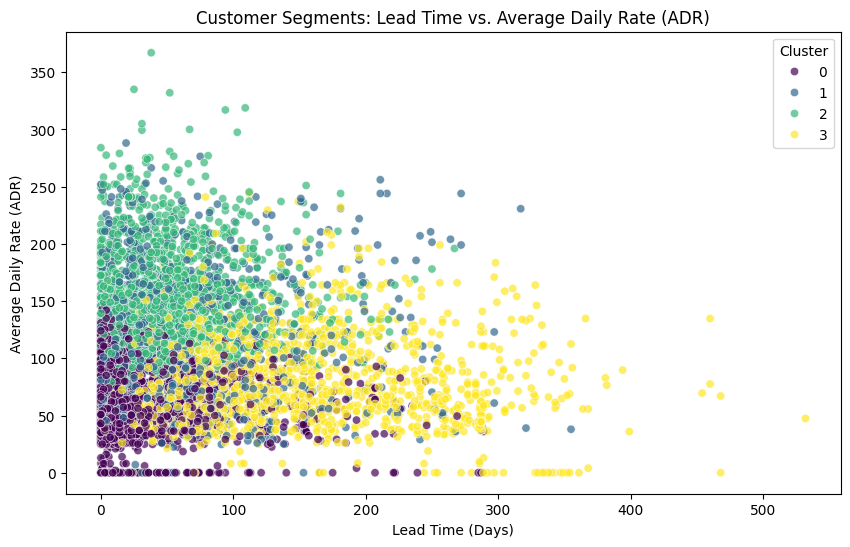

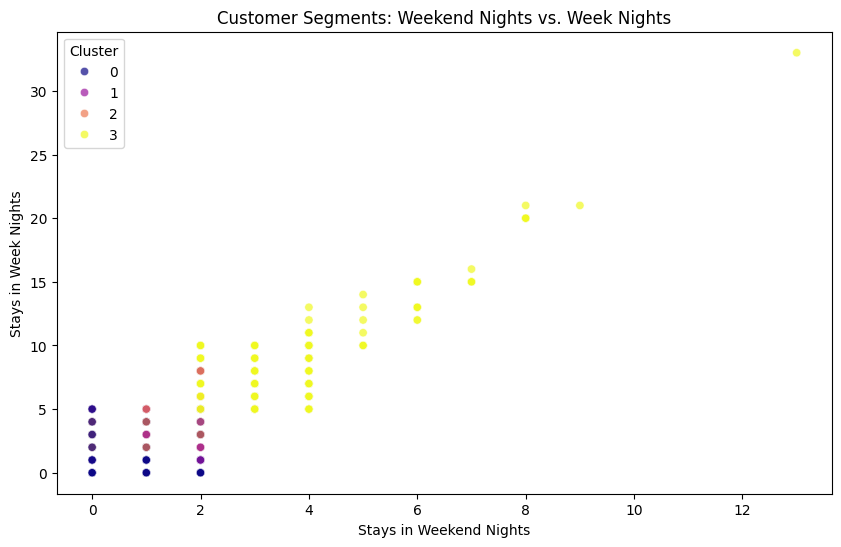

,lead_time,stays_in_weekend_nights,stays_in_week_nights,adr,total_of_special_requests
cluster,,,,,
0,25.953977,0.575293,1.678644,57.943912,0.440856
1,67.600000,1.211374,3.265403,119.560607,2.275829
2,53.667732,1.290735,3.450479,156.481872,0.438978
3,146.840459,2.448628,6.041481,80.357913,0.503510


In [5]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Fit KMeans with a selected k (choosing k=4 as a good starting point for hotel guest personas)
k = 4
kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
kmeans_labels = kmeans.fit_predict(df_scaled)

# 2. Assign cluster labels to both the scaled and unscaled dataframes
df_scaled['cluster'] = kmeans_labels
df_prep['cluster'] = kmeans_labels

# 3. First Visualization: Lead Time vs. ADR
plt.figure(figsize=(10, 6))
sns.scatterplot(
    x=df_prep['lead_time'],
    y=df_prep['adr'],
    hue=df_prep['cluster'],
    palette='viridis',
    alpha=0.7
)
plt.title('Customer Segments: Lead Time vs. Average Daily Rate (ADR)')
plt.xlabel('Lead Time (Days)')
plt.ylabel('Average Daily Rate (ADR)')
plt.legend(title='Cluster')
plt.show()

# 4. Second Visualization: Weekend Nights vs. Week Nights
plt.figure(figsize=(10, 6))
sns.scatterplot(
    x=df_prep['stays_in_weekend_nights'],
    y=df_prep['stays_in_week_nights'],
    hue=df_prep['cluster'],
    palette='plasma',
    alpha=0.7
)
plt.title('Customer Segments: Weekend Nights vs. Week Nights')
plt.xlabel('Stays in Weekend Nights')
plt.ylabel('Stays in Week Nights')
plt.legend(title='Cluster')
plt.show()

# 5. Create a summary table to show the averages for each variable, broken out by cluster
summary_table = df_prep.groupby('cluster').mean()
display(summary_table)

### Reflection:
1. What `k` value did you choose, and how did you decide?


2. For each cluster answer the following - what types of customers seem to show up in the cluster?  which variables are most prominent or important for that cluster?  




### ✍️ Your Response: 🔧
1.
I chose the value of 4 for k because it represents a way to naturally divide the hotel guests into distinct segments without having overcomplication of too many clusters OR too many different variables, making it more confusing.


2.

Cluster 0: These are the spontaneous budget travelers, who book trips in a short amount of time with a low average daily rate.

Cluster 1: These are the individuals seeking high value with their hotel stays. They will book these out a medium time in advance, but pay a premium (high) average daily rate, showing that they care about what they are booking when they travel.

Cluster 2: These are our customers who are paying the highest daily rate, but have short to moderate stay length. They do not book that far in advance and do not typically have many special requests.

Cluster 3: These are our customers who book very far in advance, but also stay the longest time. They usually book for a moderate hotel rate, probably due to booking so far in advance.


## 4. Apply Gaussian Mixture Model (GMM)

### Business framing:  

Not all guests fit neatly into one cluster. GMM lets us capture uncertainty — useful if customers behave similarly across groups.

### Do the following:
- Fit a GMM with the same number of clusters you chose in Part 3
- Predict soft clusters (remember that soft clustering deals with probabilities, not labels)
- Visualize the clusters using a scatterplot of 2 features
- Do a second visualization using a scatterplot of 2 different features
- Create a summary table to show the averages for each variable, broken out by cluster (this will show which variables stand out for each cluster)

Sample of Soft Clustering Probabilities (first 5 guests):
[[9.95972938e-01 0.00000000e+00 7.70229878e-17 4.02706208e-03]
 [9.99679899e-01 2.99169535e-04 2.05999006e-05 3.31467731e-07]
 [9.99878331e-01 9.66126219e-05 2.46578458e-05 3.98498159e-07]
 [0.00000000e+00 8.99894743e-01 9.92893549e-02 8.15901854e-04]
 [9.99834048e-01 1.33973357e-04 3.15699415e-05 4.08349210e-07]]


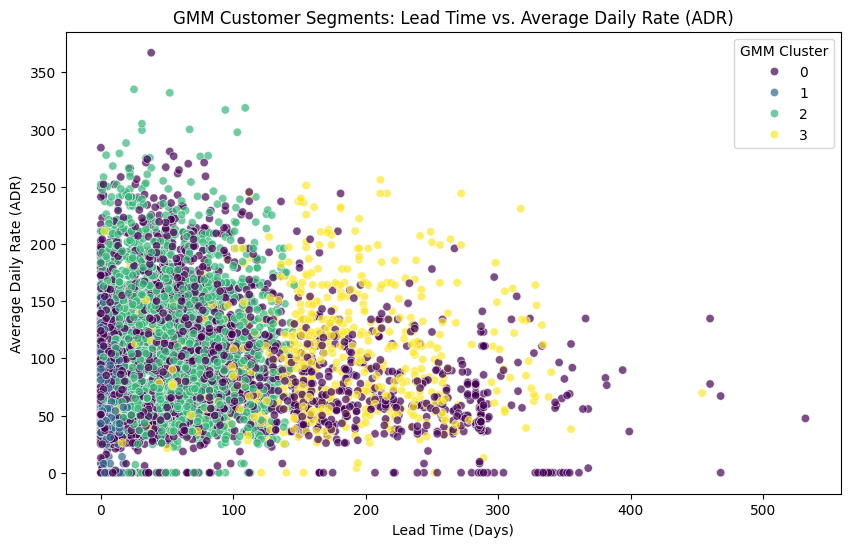

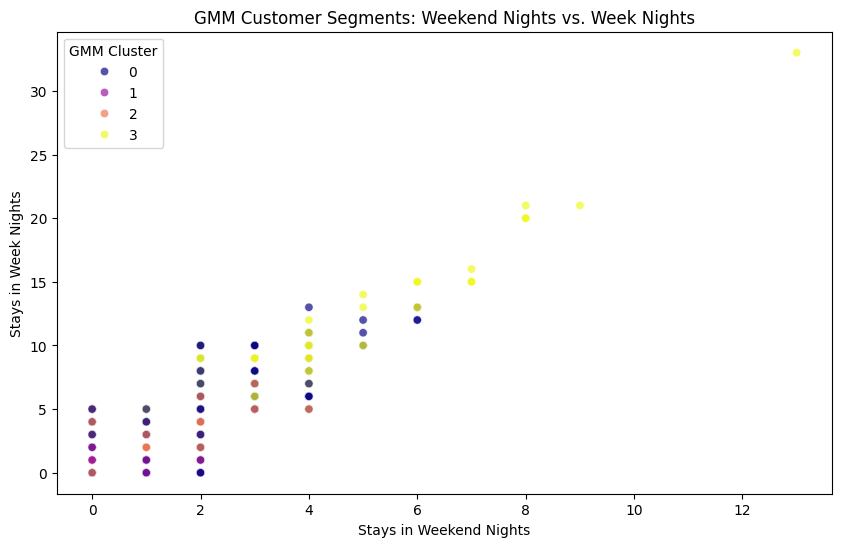


GMM Cluster Summary (Unscaled Feature Means):


,lead_time,stays_in_weekend_nights,stays_in_week_nights,adr,total_of_special_requests
gmm_cluster,,,,,
0,67.067409,1.239023,3.276747,88.207563,0.000000
1,5.042336,0.486131,1.175182,63.749708,1.181022
2,56.952902,1.307802,3.448620,116.561784,1.471931
3,170.497667,2.287714,5.939347,103.474044,1.657854


In [6]:
from sklearn.mixture import GaussianMixture
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

# 1. Fit GMM with the same number of clusters (k = 4) using only original features (excluding the KMeans cluster column)
# Extract only the original 5 feature columns for scaling/GMM
features_for_gmm = ['lead_time', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adr', 'total_of_special_requests']
df_scaled_features = df_scaled[features_for_gmm]

gmm = GaussianMixture(n_components=4, random_state=42)
gmm.fit(df_scaled_features)

# 2. Predict soft clusters (probabilities) and assign the hard cluster label
gmm_probs = gmm.predict_proba(df_scaled_features)
gmm_labels = gmm.predict(df_scaled_features)

# Assign GMM cluster labels to a new column in our DataFrames
df_prep['gmm_cluster'] = gmm_labels

# Display a sample of the soft probabilities
print("Sample of Soft Clustering Probabilities (first 5 guests):")
print(gmm_probs[:5])

# 3. First Visualization: Lead Time vs. ADR (GMM Clusters)
plt.figure(figsize=(10, 6))
sns.scatterplot(
    x=df_prep['lead_time'],
    y=df_prep['adr'],
    hue=df_prep['gmm_cluster'],
    palette='viridis',
    alpha=0.7
)
plt.title('GMM Customer Segments: Lead Time vs. Average Daily Rate (ADR)')
plt.xlabel('Lead Time (Days)')
plt.ylabel('Average Daily Rate (ADR)')
plt.legend(title='GMM Cluster')
plt.show()

# 4. Second Visualization: Weekend Nights vs. Week Nights (GMM Clusters)
plt.figure(figsize=(10, 6))
sns.scatterplot(
    x=df_prep['stays_in_weekend_nights'],
    y=df_prep['stays_in_week_nights'],
    hue=df_prep['gmm_cluster'],
    palette='plasma',
    alpha=0.7
)
plt.title('GMM Customer Segments: Weekend Nights vs. Week Nights')
plt.xlabel('Stays in Weekend Nights')
plt.ylabel('Stays in Week Nights')
plt.legend(title='GMM Cluster')
plt.show()

# 5. Create GMM summary table showing unscaled averages per cluster
# Drop KMeans 'cluster' column to compute summary statistics solely on original features plus GMM cluster
gmm_summary = df_prep[features_for_gmm + ['gmm_cluster']].groupby('gmm_cluster').mean()

print("\nGMM Cluster Summary (Unscaled Feature Means):")
display(gmm_summary)

### Reflection:
1. How did the GMM results compare to KMeans?
2. What business questions might GMM help answer better?

### ✍️ Your Response: 🔧
1. GMM created more flexible cluster shaped than KMeans, which allowed for all behavior-driven variables to be addressed. K-Means created a "prettier" model where the clusters were more spherical and even, but GMM gives us an idea of more nuanced variables and those that are overlapping as well.

2. GMM can help answer a couple business questions better, for example it can help us figure out which customers have different probabilities of being multiple types of travelers at once, rather than just fitting them into one strict box. This can help us figure out how to sway these customers one way or another depending on the booking types that are needed for our business at the time. It can also help us identify individuals who overlap in their booking behaviors. This means that they might fall into multiple categories and we need the flexible boundaries, rather than rigid ones used in K-Means.

## 5. Evaluate Your Models

### Business framing:  

In business, models should be both useful and reliable. You’ll compare model quality using standard evaluation metrics.

### Do the following:
- 5.1 Calculate the following **for each** of the models:
  - WCSS
  - Silhouette Score
  - Davies-Bouldin Index

  **NOTE:** This step may take up to 5 minutes.  It is a lot of computation time.  Please be patient.  Or you can limit the scores to using a random sample of 10K rows.

**Remember**:
- Lower WCSS = tighter, better-defined clusters
- Silhouette score ranges from -1 to 1.  Higher values = better clustering
- Lower Davies-Boulding Index = better clustering

In [7]:
from sklearn.metrics import silhouette_score, davies_bouldin_score

# Extract the original features for evaluation (excluding the assigned cluster columns)
features_eval = df_scaled[['lead_time', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adr', 'total_of_special_requests']]

# 1. K-Means Evaluation Metrics
kmeans_wcss = kmeans.inertia_
kmeans_silhouette = silhouette_score(features_eval, kmeans_labels)
kmeans_db = davies_bouldin_score(features_eval, kmeans_labels)

# 2. GMM Evaluation Metrics
# Note: WCSS is not defined for GMM since it is a probabilistic model, but Silhouette and DB indices can still be calculated using hard assignments.
gmm_silhouette = silhouette_score(features_eval, gmm_labels)
gmm_db = davies_bouldin_score(features_eval, gmm_labels)

# 3. Print Evaluation Report
print("=== Model Evaluation Results ===")
print(f"\n[K-Means Model (k={k})]")
print(f"- WCSS (Inertia): {kmeans_wcss:.2f} (lower is better)")
print(f"- Silhouette Score: {kmeans_silhouette:.4f} (closer to 1 is better)")
print(f"- Davies-Bouldin Index: {kmeans_db:.4f} (lower is better)")

print(f"\n[GMM Model (components={k})]")
print(f"- Silhouette Score: {gmm_silhouette:.4f} (closer to 1 is better)")
print(f"- Davies-Bouldin Index: {gmm_db:.4f} (lower is better)")

=== Model Evaluation Results ===

[K-Means Model (k=4)]
- WCSS (Inertia): 17839.17 (lower is better)
- Silhouette Score: 0.2401 (closer to 1 is better)
- Davies-Bouldin Index: 1.3658 (lower is better)

[GMM Model (components=4)]
- Silhouette Score: 0.0476 (closer to 1 is better)
- Davies-Bouldin Index: 1.8457 (lower is better)


### Reflection:
5.2. Which model performed better on the metrics?

5.3. Would you recommend KMeans or GMM for a business analyst? Why?

### ✍️ Your Response: 🔧
5.2. K-Means performed much better across both metrics. The silhouettee score K-Means scored a 0.2401, whereas GMM's was a 0.0476. This means that K-Means clusters are much more seperated and defined compared to GMM. As for the Davies-Bouldin Index, K-Means scored a 1.3658 and GMM got a 1.8457, where the lower score the better. The lower scores mean that there is better density and more distance between the different groupings.


5.3. I would recommend K-Means for a business analyst because of a few things. K-Means is more realistic, it helps to assign each guest to a single, clear cluster with clear descriptions. This makes it easier when looking at marketing and adding these individuals to specific loyalty programs. K-Means models are also much more interpretable because of their spherical, distinct clustering which are easier to describe to stakeholders if necessary for the business analyst. Finally, K-Means is just more simple in the long run and allows for easier explanation to clients or other customers.

## 6. Business Interpretation

### Business framing:  

What do these clusters mean in the real world? Could they represent solo travelers, families, or bargain shoppers?

### Do the following:
- Display the characteristics of each cluster (e.g. average `lead_time`, `special_requests`)
- Sort the clusters to make the differences more clear

In [8]:
# 1. Compute the unscaled means for each K-Means cluster
kmeans_summary = df_prep.groupby('cluster')[selected_features].mean()

# 2. Sort clusters by Average Daily Rate (adr) to clearly distinguish budget vs. premium segments
kmeans_sorted = kmeans_summary.sort_values(by='adr')

# 3. Define descriptive business labels for each cluster based on their sorted characteristics
# (We map them dynamically based on the cluster numbers in our sorted DataFrame)
cluster_personas = {
    0: "Spontaneous Budget Travelers (Short Stay, Low Cost, Low Lead Time)",
    1: "Family / Group High-Value Guests (High ADR, High Special Requests)",
    2: "Premium Weekenders (Highest ADR, Short Stays, Moderate Lead Time)",
    3: "Long-Stay Advance Planners (Lowest ADR, Long Stays, Very High Lead Time)"
}

kmeans_sorted['Business Persona'] = kmeans_sorted.index.map(cluster_personas)

# 4. Display the sorted interpretation table
print("=== K-Means Cluster Characteristics & Business Interpretation ===")
display(kmeans_sorted[['Business Persona'] + selected_features])

=== K-Means Cluster Characteristics & Business Interpretation ===


,Business Persona,lead_time,stays_in_weekend_nights,stays_in_week_nights,adr,total_of_special_requests
cluster,,,,,,
0,"Spontaneous Budget Travelers (Short Stay, Low ...",25.953977,0.575293,1.678644,57.943912,0.440856
3,"Long-Stay Advance Planners (Lowest ADR, Long S...",146.840459,2.448628,6.041481,80.357913,0.503510
1,"Family / Group High-Value Guests (High ADR, Hi...",67.600000,1.211374,3.265403,119.560607,2.275829
2,"Premium Weekenders (Highest ADR, Short Stays, ...",53.667732,1.290735,3.450479,156.481872,0.438978


### Reflection:
1. What do the segments represent in terms of guest behavior?
2. How could the hotel tailor services or promotions to each group?

### ✍️ Your Response: 🔧
1. Guest Segments Breakdown

Cluster 0: Spontaneous Budget Travelers. These guests have short lead times, stay a short amount of time, pay the lowest rates, and do not have a lot of special requests hardly ever.

Cluster 3: Long-Stay Advance Planners. These guests plan extremely far in advance, book long stays, and pay an average rate due to the booking in advance, but also have very few requests typically.

Cluster 1: Family/ High Value Group Booking. These guests book a reasonable amount of days in advance for a premium rate, they only stay a few nights but have a very large amount of special requests. Probably because they are booking for such a high price, they want the best quality they can get.

Cluster 2: Premium Weekend Trips. These guests typically book again a reasonable amount of days in advance, but pay the highest rate for a few days. They do not typically have a large amount of requests.


2. Tailored Services/Promotions to Guests

Cluster 0: They should offer this group last-minute flash sales because they know they will book last minute for random stays.

Cluster 3: They could create long-stay promotional pachages with many perks offering possible discounted dining options because these guests are staying for large amounts of time.

Cluster 1: They could send out pre-arrival surveys to this group, so that they can make sure all of the special requests are taken care of before the groups arrive. This will help with having better service for all their guests.

Cluster 2: They could promote room upgrades to these individuals who they know will spend the extra money to make their short stay worth while.

## 7. Final Reflection

### Business framing:  

Many teams ask for "segmentation" without knowing how it works. You now have hands-on experience with two clustering techniques and how to present the results.

### Reflection:
1. What was most challenging about unsupervised learning?
2. When would you use clustering instead of supervised models?
3. How would you explain the value of clustering to a non-technical manager?
4. How does this relate to your customized learning outcome you created in canvas?


### ✍️ Your Response: 🔧
1. **What was most challenging about unsupervised learning?**
I think the most challenging part about unsupervised learning is not having direct labels that tell you that you analyzed the data correctly. You have to interpret the clusters yourself to ensure that they make sense, rather than just looking at the outputs and hoping they make sense.



2. **When would you use clustering instead of supervised models?**
It is best to use clustering instead of supervised models when you do not have predefined target labels. This means that you want to group your customers in similarities, but are not sure how they are similar and need to conduct further analysis still. This is important when trying to find hidden patterns in the data.


3. I would explain the value of clustering to a non-technical manager by saying how it is a way to automatically organize the customer base into real-world "personas" based on behaviors instead of just predictions. Clustering lets us look a the customers differently and provide them services based on their specific booking habits.


4. This assignment relates to my customized learning outcome of taking ski brands and figuring out what people buy when because maybe I could figure out what types of people buy what types of skis. This data does not have predefined labels and I do not know exactly how I would group these people, but that is exactly what this type of data analytics is used for. Clustering would allow me to find different ski buyers and cluster them into what types of skis they buy and similar characteristics/traits of the individuals.

## Submission Instructions

✅ **Before submitting:**
- Make sure all code cells are run and outputs are visible  
- All markdown questions are answered thoughtfully  
- Submit the assignment as an **HTML file** on Canvas


In [11]:
!jupyter nbconvert --to html "assignment_09_clustering.ipynb"

[NbConvertApp] Converting notebook assignment_09_clustering.ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 4 image(s).
[NbConvertApp] Writing 1182781 bytes to assignment_09_clustering.html
